# CS3920/CS5920 Lab Worksheet 8: Neural nets and SVM (NO MGLEARN)

In [3]:
# In[1]:
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

X, y = make_moons(n_samples=100, noise=0.25, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

mlp = MLPClassifier(
    solver='lbfgs',
    activation='tanh',
    random_state=42,
    hidden_layer_sizes=[10]
).fit(X_train, y_train)

plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=60)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")


Text(0, 0.5, 'Feature 1')

In [4]:
# In[2]:
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, s=60)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")


Text(22.097222222222214, 0.5, 'Feature 1')

In [5]:
# In[3]:
y_hat = mlp.predict(X_test)

plt.scatter(X_test[:, 0], X_test[:, 1], c=y_hat, s=60)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

# How many mistakes?
num_mistakes = np.sum(y_hat != y_test)
print("Number of mistakes on test set:", num_mistakes)
print("Test accuracy:", np.mean(y_hat == y_test))

Number of mistakes on test set: 3
Test accuracy: 0.88


In [6]:
# In[4]:
from sklearn.svm import LinearSVC

X = np.genfromtxt("make_forge_X.txt")
y = np.genfromtxt("make_forge_y.txt")

svm = LinearSVC().fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=60)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")


Text(30.972222222222214, 0.5, 'Feature 1')

In [7]:
# In[5]:
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, random_state=42
)

svc = SVC()
svc.fit(X_train, y_train)

print("Accuracy on training set:", svc.score(X_train, y_train))
print("Accuracy on test set:", svc.score(X_test, y_test))


Accuracy on training set: 0.9107981220657277
Accuracy on test set: 0.951048951048951


In [8]:
# In[6]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

svc.fit(X_train_scaled, y_train)

print("Accuracy on training set:", svc.score(X_train_scaled, y_train))
print("Accuracy on test set:", svc.score(X_test_scaled, y_test))


Accuracy on training set: 0.9835680751173709
Accuracy on test set: 0.9790209790209791


In [9]:
# In[7]:
svc = SVC(C=1000)
svc.fit(X_train_scaled, y_train)

print("Accuracy on training set:", svc.score(X_train_scaled, y_train))
print("Accuracy on test set:", svc.score(X_test_scaled, y_test))


Accuracy on training set: 1.0
Accuracy on test set: 0.951048951048951


In [10]:
# In[8]:
from sklearn.datasets import make_blobs

X, y = make_blobs(random_state=42)

plt.scatter(X[:, 0], X[:, 1], c=y, s=60)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")


Text(44.222222222222214, 0.5, 'Feature 1')

In [11]:
# In[9]:
svm = LinearSVC().fit(X, y)

print("Coefficient shape:", svm.coef_.shape)
print("Intercept shape:", svm.intercept_.shape)

# Optional: also print the actual coefficients to inspect rows 0,1,2 for Exercise 1
print("svm.coef_:\n", svm.coef_)
print("svm.intercept_:\n", svm.intercept_)


Coefficient shape: (3, 2)
Intercept shape: (3,)
svm.coef_:
 [[-0.17492412  0.23140766]
 [ 0.47622012 -0.06936786]
 [-0.18914207 -0.20400079]]
svm.intercept_:
 [-1.07745775  0.13139239 -0.08604962]


In [12]:
# In[10]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=60)

line = np.linspace(-15, 15)

for coef, intercept, color in zip(svm.coef_, svm.intercept_, ['b', 'r', 'g']):
    plt.plot(line, -(line * coef[0] + intercept) / coef[1], c=color)

plt.ylim(-10, 15)
plt.xlim(-10, 8)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")


Text(30.972222222222214, 0.5, 'Feature 1')

## Exercises

### Task 1

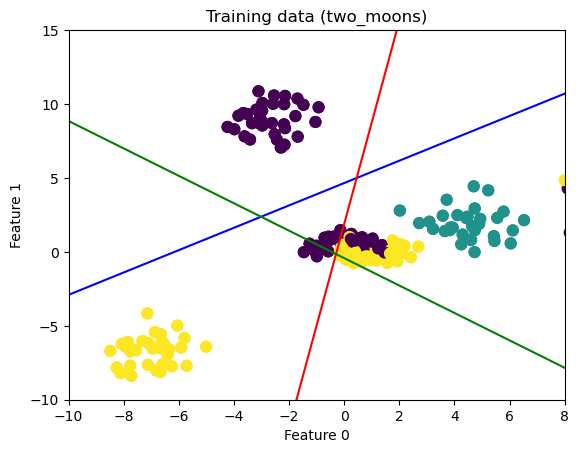

In [13]:
# Task 1 – Neural network on two_moons

from sklearn.neural_network import MLPClassifier
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
%matplotlib inline
import matplotlib.pyplot as plt

# Generate data
X, y = make_moons(n_samples=100, noise=0.25, random_state=42)

# Train–test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=42
)

# Define and fit MLP
mlp = MLPClassifier(
    solver='lbfgs',
    activation='tanh',
    random_state=42,
    hidden_layer_sizes=[10]
).fit(X_train, y_train)

# Plot training data
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=60)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
plt.title("Training data (two_moons)")
plt.show()


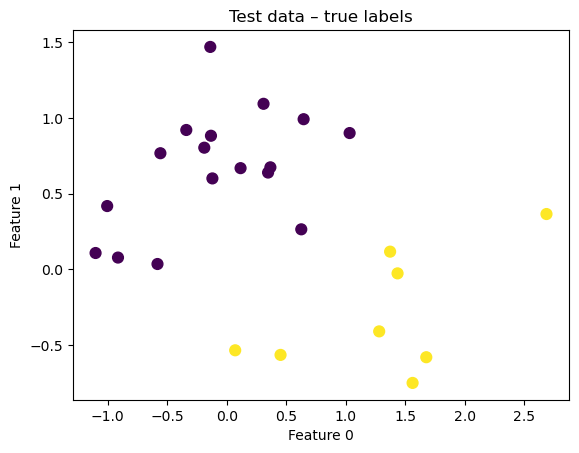

In [14]:
# Visualise test set with true labels

plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, s=60)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
plt.title("Test data – true labels")
plt.show()


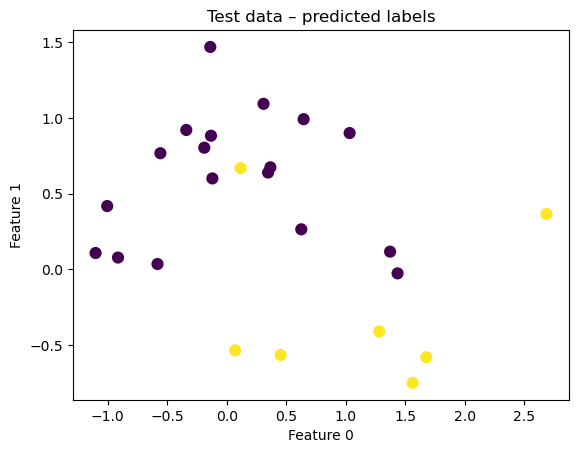

Number of misclassified test points: 3
Test accuracy: 0.88


In [15]:
# Visualise test set with predicted labels and count mistakes

y_hat = mlp.predict(X_test)

plt.scatter(X_test[:, 0], X_test[:, 1], c=y_hat, s=60)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
plt.title("Test data – predicted labels")
plt.show()

errors = (y_hat != y_test).sum()
accuracy = mlp.score(X_test, y_test)
print("Number of misclassified test points:", errors)
print("Test accuracy:", accuracy)


This task trains an MLPClassifier on the two_moons dataset, which contains two curved clusters that cannot be separated by a straight line. The chosen network uses the lbfgs solver, the tanh activation function, and a single hidden layer of size 10. This smaller network is sufficient because the dataset is very small and does not require a large architecture.

On the training set, the classifier learns a curved decision boundary that follows the shape of the two moons. A linear classifier would not be able to achieve this.

On the test set, the true labels are plotted first. After predicting the labels using y_hat = mlp.predict(X_test), a second plot shows the predicted labels. The number of misclassified test points is obtained by summing y_hat != y_test, and the test accuracy is computed with numpy or mlp.score.

The network usually makes only a small number of mistakes because even a simple neural network with tanh activation can model the non-linear structure of the dataset well.


### Task 2

This task applies LinearSVC to the forge dataset. The linear SVM tries to separate the two classes using a straight decision boundary. Since the forge dataset is not perfectly linearly separable, the classifier correctly labels most points but still misclassifies some. This is expected when the classes overlap or when a straight boundary cannot perfectly divide them.

LinearSVC uses a regularisation parameter C. A small value of C leads to stronger regularisation, producing a simpler boundary that may misclassify more points but generalises better. A large value of C leads the model to try to classify every training point correctly, which can cause the boundary to tilt or shift in a way that overfits individual points.

The interpretation is that a linear SVM often cannot perfectly solve non-linear patterns but still finds a reasonable compromise between accuracy and simplicity.

### Task 3

First, an RBF-kernel SVM is trained on the original breast cancer data without any scaling. The training accuracy is high but the test accuracy is lower than expected because the SVM is sensitive to differences in feature scale. Some features have much larger numerical ranges than others, which distorts the distance calculations used by the RBF kernel.

After applying MinMaxScaler to both the training and test sets, the SVM achieves substantially higher performance. Scaling ensures that all features contribute more evenly to the model, and as a result the decision boundary becomes more effective. The training accuracy increases and the test accuracy improves noticeably.

Finally, setting C = 1000 causes overfitting. The model achieves almost perfect accuracy on the training set but performs worse on the test set. A very large C forces the classifier to fit the training data as closely as possible, including noise, which harms generalisation.

The task demonstrates that scaling is essential for kernel SVMs and that the regularisation parameter C must be chosen carefully to balance fitting the data and avoiding overfitting.